# Letters-only linguistic bigrams in ED

Start with the quick comparison below, then inspect the selected tokenizer's bigram usage in detail. The default is the **letters-only linguistic bigram**; change `TOKENIZER` to inspect another vocabulary.

The letters-only option was added to TVA's bigram trainer. It skips pairs containing spaces, digits or punctuation **when counting candidate bigrams** (`letters_only=True`, `tva/tokenizers.py`). It still keeps these characters as individual tokens, including the space category and spaces in recognition targets. It does not remove spaces or join letters across word boundaries.

The notebook compares the original TVA linguistic bigram, its letters-only variant, and the current handwriting `bigram_v3`. Each has 145 bigrams and 224 classes. All vocabularies were learned from IAM. ED labels are used here only for analysis; **nothing is trained or selected**.

It answers:

1. Which pairs were removed or added by the letters-only restriction?
2. Are spaces still encoded and decoded correctly?
3. How does merging and recognition performance compare?
4. Which letters-only bigrams are frequent, rare or unused, and how do train and validation differ?

**Counting rule:** count only tokens actually emitted by greedy left-to-right encoding, not every overlapping pair. Case, spaces and punctuation are kept. Every recording counts, so repeated sentences count repeatedly.

WD and WI contain the same 2,550 recordings, so pooled counts are identical; only their train/validation splits differ. Recognition summaries use CER and WER from the same best-CER epoch and only complete 300-epoch runs.

In [1]:
# Locate the repository before importing TVA or opening local files.
import os
import sys
from pathlib import Path

REPO_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'main.py').is_file() and (p / 'tva').is_dir()
)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.chdir(REPO_ROOT)

%matplotlib inline
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import Markdown, display

from loguru import logger
from tva.ed_analysis import js_divergence, load_records, load_tokenizer, saved_scores, show, show_table, token_counts

logger.disable('tva')  # hide routine 'tokenizer loaded' messages

# ---- Settings: change these, then run all cells ----
TOKENIZER = 'linguistic_bigram_letters'  # default: letters-only IAM linguistic bigram
# Alternatives: 'linguistic_bigram_tva' (original TVA, may join spaces),
#               'handwriting_bigram' (current v3 connectivity-selected pairs)
SPLITS = ['wd', 'wi']
FOLD = 0
TOP_N = 30   # 145 shows every vocabulary bigram

assert SPLITS and len(set(SPLITS)) == len(SPLITS) and set(SPLITS) <= {'wd', 'wi'}
assert FOLD in range(5) and TOP_N > 0

tokenizer = load_tokenizer(TOKENIZER)
bigrams = [token for token in tokenizer.vocab if len(token) == 2]
print(f'{TOKENIZER}: {len(bigrams)} bigrams, {tokenizer.size} classes including blank')

linguistic_bigram_letters: 145 bigrams, 224 classes including blank


## Quick comparison: what does letters-only change?

The three vocabularies have the same singleton alphabet and total size. The first table counts **available** bigrams and compression on the same pooled ED labels. A space-containing pair can also contain punctuation, so the diagnostic columns are not mutually exclusive. Characters per token means total characters divided by emitted tokens; higher means more merging.

The second table lists pairs unique to each linguistic vocabulary, in their IAM frequency-rank order. The trainer fills all 145 slots with the most frequent eligible pairs: this **replaces** excluded pairs rather than just deleting them. IAM counts count each distinct training line once, following TVA's trainer.

In [2]:
COMPARISON_NAMES = {
    'linguistic_bigram_tva': 'Original TVA linguistic',
    'linguistic_bigram_letters': 'Letters-only linguistic',
    'handwriting_bigram': 'Handwriting v3',
}
comparison_tokenizers = {key: load_tokenizer(key) for key in COMPARISON_NAMES}
comparison_labels = [record['label'] for part in ('train', 'val')
                     for record in load_records(SPLITS[0], FOLD, part)]
comparison_chars = sum(map(len, comparison_labels))
base_characters = {token for token in comparison_tokenizers['linguistic_bigram_tva'].vocab
                   if len(token) < 2}
comparison_pairs = {}
rows = []
for key, candidate in comparison_tokenizers.items():
    pairs = {token for token in candidate.vocab if len(token) == 2}
    comparison_pairs[key] = pairs
    assert candidate.size == 224 and len(pairs) == 145
    assert {token for token in candidate.vocab if len(token) < 2} == base_characters
    encoded_count = sum(len(candidate.encode(text)) for text in comparison_labels)
    rows.append({'Tokenizer': COMPARISON_NAMES[key], 'Classes': candidate.size,
                 'Bigrams': len(pairs), 'Letter-only pairs': sum(t.isalpha() for t in pairs),
                 'Pairs containing space': sum(' ' in t for t in pairs),
                 'Space singleton retained': ' ' in candidate.vocab,
                 'Characters/token (pooled ED)': f'{comparison_chars / encoded_count:.3f}',
                 'Tokens/sentence (pooled ED)': f'{encoded_count / len(comparison_labels):.1f}'})
assert all(t.isalpha() for key in ('linguistic_bigram_letters', 'handwriting_bigram')
           for t in comparison_pairs[key])
show_table(rows)

original_only = sorted(comparison_pairs['linguistic_bigram_tva'] - comparison_pairs['linguistic_bigram_letters'],
                       key=comparison_tokenizers['linguistic_bigram_tva'].vocab.get)
letters_only_added = sorted(comparison_pairs['linguistic_bigram_letters'] - comparison_pairs['linguistic_bigram_tva'],
                            key=comparison_tokenizers['linguistic_bigram_letters'].vocab.get)
common_pairs = comparison_pairs['linguistic_bigram_tva'] & comparison_pairs['linguistic_bigram_letters']
print(f'Linguistic vocabularies: {len(common_pairs)} shared pairs; '
      f'{len(original_only)} original-only pairs; {len(letters_only_added)} letters-only additions.')
print('All original-only pairs:', ', '.join(show(t) for t in original_only))
show_table([{'Original-only pair': show(original_only[i]) if i < len(original_only) else '',
             'IAM count (original)': comparison_tokenizers['linguistic_bigram_tva'].scores.get(original_only[i], '') if i < len(original_only) else '',
             'Added letter pair': show(letters_only_added[i]) if i < len(letters_only_added) else '',
             'IAM count (letters only)': comparison_tokenizers['linguistic_bigram_letters'].scores.get(letters_only_added[i], '') if i < len(letters_only_added) else ''}
            for i in range(min(TOP_N, max(len(original_only), len(letters_only_added))))])

Linguistic vocabularies: 109 shared pairs; 36 original-only pairs; 36 letters-only additions.
All original-only pairs: 'e ', ' t', 's ', ' a', 't ', 'd ', 'n ', ' o', ' w', ' i', 'r ', 'y ', ' s', ', ', ' h', ' b', 'o ', '. ', 'f ', ' f', ' c', ' p', ' m', 'a ', 'l ', 'g ', 'h ', ' d', ' n', ' e', ' r', ' l', ' M', ' g', 'r.', ' u'


| Tokenizer | Classes | Bigrams | Letter-only pairs | Pairs containing space | Space singleton retained | Characters/token (pooled ED) | Tokens/sentence (pooled ED) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Original TVA linguistic | 224 | 145 | 109 | 35 | True | 1.499 | 27.8 |
| Letters-only linguistic | 224 | 145 | 145 | 0 | True | 1.342 | 31.0 |
| Handwriting v3 | 224 | 145 | 145 | 0 | True | 1.246 | 33.4 |

| Original-only pair | IAM count (original) | Added letter pair | IAM count (letters only) |
| --- | --- | --- | --- |
| 'e ' | 6281 | 'gh' | 375 |
| ' t' | 5156 | 'su' | 373 |
| 's ' | 3772 | 'na' | 371 |
| ' a' | 3530 | 'ry' | 370 |
| 't ' | 3154 | 'os' | 365 |
| 'd ' | 3088 | 'op' | 364 |
| 'n ' | 2846 | 'ab' | 352 |
| ' o' | 2124 | 'wo' | 348 |
| ' w' | 1972 | 'im' | 347 |
| ' i' | 1881 | 'vi' | 341 |
| 'r ' | 1860 | 'fe' | 340 |
| 'y ' | 1832 | 'bl' | 337 |
| ' s' | 1784 | 'rn' | 334 |
| ', ' | 1735 | 'oo' | 332 |
| ' h' | 1728 | 'rd' | 331 |
| ' b' | 1592 | 'od' | 328 |
| 'o ' | 1520 | 'ia' | 327 |
| '. ' | 1513 | 'mp' | 326 |
| 'f ' | 1328 | 'ei' | 323 |
| ' f' | 1283 | 'av' | 320 |
| ' c' | 1279 | 'ov' | 311 |
| ' p' | 1168 | 'ey' | 310 |
| ' m' | 1084 | 'am' | 307 |
| 'a ' | 933 | 'ci' | 304 |
| 'l ' | 931 | 'tt' | 301 |
| 'g ' | 909 | 'sa' | 298 |
| 'h ' | 863 | 'rm' | 297 |
| ' d' | 799 | 'bo' | 290 |
| ' n' | 705 | 'fr' | 289 |
| ' e' | 652 | 'ap' | 282 |

### Spaces are still recognition targets

Quotes make a space visible as `' '`. For example, the original vocabulary may emit `'e '` while the letters-only vocabulary emits `'e'`, `' '`. Both must decode to the exact input. The same applies to digits and punctuation, which remain single characters in letters-only vocabularies.

In [3]:
EXAMPLES = ['the cat', 'In short, there will be on TV!', '42 + 3 = 45%']
rows = []
for text in EXAMPLES:
    for key, candidate in comparison_tokenizers.items():
        ids = candidate.encode(text)
        tokens = [candidate.idx_token[i] for i in ids]
        assert candidate.decode(ids) == text
        assert 0 not in ids
        if key != 'linguistic_bigram_tva':
            assert tokens.count(' ') == text.count(' ')
            assert all(t.isalpha() for t in tokens if len(t) == 2)
        rows.append({'Input': show(text), 'Tokenizer': COMPARISON_NAMES[key],
                     'Emitted tokens': ', '.join(show(t) for t in tokens),
                     'Exact round trip': candidate.decode(ids) == text})
show_table(rows)

| Input | Tokenizer | Emitted tokens | Exact round trip |
| --- | --- | --- | --- |
| 'the cat' | Original TVA linguistic | 'th', 'e ', 'ca', 't' | True |
| 'the cat' | Letters-only linguistic | 'th', 'e', ' ', 'ca', 't' | True |
| 'the cat' | Handwriting v3 | 'th', 'e', ' ', 'ca', 't' | True |
| 'In short, there will be on TV!' | Original TVA linguistic | 'I', 'n ', 'sh', 'or', 't', ', ', 'th', 'er', 'e ', 'wi', 'll', ' b', 'e ', 'on', ' ', 'T', 'V', '!' | True |
| 'In short, there will be on TV!' | Letters-only linguistic | 'I', 'n', ' ', 'sh', 'or', 't', ',', ' ', 'th', 'er', 'e', ' ', 'wi', 'll', ' ', 'be', ' ', 'on', ' ', 'T', 'V', '!' | True |
| 'In short, there will be on TV!' | Handwriting v3 | 'I', 'n', ' ', 's', 'ho', 'r', 't', ',', ' ', 'th', 'er', 'e', ' ', 'w', 'i', 'll', ' ', 'be', ' ', 'on', ' ', 'T', 'V', '!' | True |
| '42 + 3 = 45%' | Original TVA linguistic | '4', '2', ' ', '+', ' ', '3', ' ', '=', ' ', '4', '5', '%' | True |
| '42 + 3 = 45%' | Letters-only linguistic | '4', '2', ' ', '+', ' ', '3', ' ', '=', ' ', '4', '5', '%' | True |
| '42 + 3 = 45%' | Handwriting v3 | '4', '2', ' ', '+', ' ', '3', ' ', '=', ' ', '4', '5', '%' | True |

### Recognition scores for the selected fold

These are saved recognizer results, not scores from the label-count analysis. Both metrics come from the **best-CER epoch**, matching `docs/EXPERIMENTS.md`. Missing or incomplete runs stay blank. Only the current handwriting `v3` results are compared here.

Changing vocabulary membership also changes token usage and compression. This comparison alone does not establish that spaces or connectivity cause a recognition difference. The compression and drawn-vocabulary controls are in the compression notebook and experiment log.

In [4]:
rows = []
for split in SPLITS:
    for key, label in COMPARISON_NAMES.items():
        score = saved_scores(key, split, FOLD)
        complete = score is not None and score['epochs'] == 300
        rows.append({'Setting': split.upper(), 'Fold': FOLD, 'Tokenizer': label,
                     'CER (%)': f"{100 * score['cer']:.4f}" if complete else '',
                     'WER at best-CER (%)': f"{100 * score['wer']:.4f}" if complete else '',
                     'Selected epoch': score['epoch'] if complete else '',
                     'Status': 'complete (300 epochs)' if complete else 'missing or incomplete'})
show_table(rows)
print(f'Detailed frequency analysis below uses: {TOKENIZER}')

Detailed frequency analysis below uses: linguistic_bigram_letters


| Setting | Fold | Tokenizer | CER (%) | WER at best-CER (%) | Selected epoch | Status |
| --- | --- | --- | --- | --- | --- | --- |
| WD | 0 | Original TVA linguistic | 35.9557 | 79.7958 | 191 | complete (300 epochs) |
| WD | 0 | Letters-only linguistic | 31.9444 | 71.8968 | 227 | complete (300 epochs) |
| WD | 0 | Handwriting v3 | 26.0665 | 66.8726 | 273 | complete (300 epochs) |
| WI | 0 | Original TVA linguistic | 20.9312 | 52.6316 | 250 | complete (300 epochs) |
| WI | 0 | Letters-only linguistic | 18.0218 | 46.5664 | 242 | complete (300 epochs) |
| WI | 0 | Handwriting v3 | 16.8772 | 45.7644 | 277 | complete (300 epochs) |

## Detailed usage of the selected bigram tokenizer

The remaining sections use `TOKENIZER`, which defaults to the letters-only linguistic vocabulary. Counts are emitted token counts, and each ED recording contributes once within its fold partition.

In [5]:
def count(records):
    tokens = token_counts(tokenizer, (tokenizer.encode(record['label']) for record in records))
    return {'records': len(records), 'tokens': sum(tokens.values()),
            'bigrams': Counter({t: n for t, n in tokens.items() if len(t) == 2})}


results = {split: {part: count(load_records(split, FOLD, part)) for part in ('train', 'val')}
           for split in SPLITS}
first = results[SPLITS[0]]
pooled = first['train']['bigrams'] + first['val']['bigrams']
pooled_total = sum(pooled.values())
ranked = sorted(bigrams, key=lambda t: (-pooled[t], t))
unused = [t for t in ranked if pooled[t] == 0]
print(f'Pooled ED (train + validation): {pooled_total:,} bigram tokens out of '
      f"{first['train']['tokens'] + first['val']['tokens']:,} tokens")

Pooled ED (train + validation): 27,009 bigram tokens out of 79,078 tokens


## 1. Summary

- **Bigram share** — the percentage of all emitted tokens that are bigrams (the rest are single characters).
- **Bigrams used** — how many of the vocabulary's bigrams occur at least once.
- **Divergence** — Jensen–Shannon divergence between the training and validation bigram frequencies of the fold: **0 = identical**, **1 = nothing in common**.
- **Concentration** — how many of the most frequent bigrams are needed to cover 50%, 80% and 95% of all bigram tokens. Small numbers mean a few bigrams dominate.

In [6]:
rows = []
for split in SPLITS:
    for part in ('train', 'val'):
        r = results[split][part]
        n = sum(r['bigrams'].values())
        rows.append({'Split': split.upper(), 'Part': part, 'Sentences': r['records'],
                     'All tokens': f"{r['tokens']:,}", 'Bigram tokens': f'{n:,}',
                     'Bigram share (%)': f"{100 * n / r['tokens']:.1f}",
                     'Bigrams used': f"{len(r['bigrams'])} of {len(bigrams)}"})
    rows.append({'Split': split.upper(), 'Part': 'train vs val', 'Sentences': '', 'All tokens': '',
                 'Bigram tokens': '', 'Bigram share (%)': '',
                 'Bigrams used': f"divergence {js_divergence(results[split]['train']['bigrams'], results[split]['val']['bigrams']):.4f}"})
show_table(rows)


def needed(share):
    covered = 0
    for rank, token in enumerate(ranked, 1):
        covered += pooled[token]
        if covered >= share * pooled_total:
            return rank


coverage = {share: needed(share) for share in (0.5, 0.8, 0.95)}
top10 = 100 * sum(pooled[t] for t in ranked[:10]) / pooled_total
show_table([{'Top 10 bigrams cover (%)': f'{top10:.1f}',
             'Bigrams for 50%': coverage[0.5], 'Bigrams for 80%': coverage[0.8],
             'Bigrams for 95%': coverage[0.95], 'Never used': f'{len(unused)} of {len(bigrams)}'}])
print('Never-used bigrams:', ', '.join(show(t) for t in unused) or '-')

Never-used bigrams: -


| Split | Part | Sentences | All tokens | Bigram tokens | Bigram share (%) | Bigrams used |
| --- | --- | --- | --- | --- | --- | --- |
| WD | train | 2047 | 63,421 | 21,451 | 33.8 | 144 of 145 |
| WD | val | 503 | 15,657 | 5,558 | 35.5 | 141 of 145 |
| WD | train vs val |  |  |  |  | divergence 0.0322 |
| WI | train | 2025 | 62,820 | 21,338 | 34.0 | 145 of 145 |
| WI | val | 525 | 16,258 | 5,671 | 34.9 | 145 of 145 |
| WI | train vs val |  |  |  |  | divergence 0.0064 |

| Top 10 bigrams cover (%) | Bigrams for 50% | Bigrams for 80% | Bigrams for 95% | Never used |
| --- | --- | --- | --- | --- |
| 23.5 | 34 | 79 | 120 | 0 of 145 |

## 2. Most frequent bigrams

`Share` and `Cumulative` use all pooled bigram tokens. The split columns give each bigram's share within that fold's training or validation bigram tokens. Spaces are visible inside quotes, e.g. `'e '` is *e* followed by a space.

In [7]:
rows, cumulative = [], 0
for rank, token in enumerate(ranked[:TOP_N], 1):
    cumulative += pooled[token]
    row = {'Rank': rank, 'Bigram': show(token), 'Count': pooled[token],
           'Share (%)': f'{100 * pooled[token] / pooled_total:.2f}',
           'Cumulative (%)': f'{100 * cumulative / pooled_total:.1f}'}
    for split in SPLITS:
        for part in ('train', 'val'):
            c = results[split][part]['bigrams']
            row[f'{split.upper()} {part} (%)'] = f'{100 * c[token] / (sum(c.values()) or 1):.2f}'
    rows.append(row)
show_table(rows)

| Rank | Bigram | Count | Share (%) | Cumulative (%) | WD train (%) | WD val (%) | WI train (%) | WI val (%) |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 'th' | 1217 | 4.51 | 4.5 | 4.49 | 4.55 | 4.44 | 4.74 |
| 2 | 'in' | 812 | 3.01 | 7.5 | 3.17 | 2.37 | 2.98 | 3.12 |
| 3 | 'is' | 664 | 2.46 | 10.0 | 2.46 | 2.46 | 2.45 | 2.49 |
| 4 | 're' | 626 | 2.32 | 12.3 | 2.36 | 2.14 | 2.30 | 2.40 |
| 5 | 'at' | 589 | 2.18 | 14.5 | 2.20 | 2.11 | 2.13 | 2.36 |
| 6 | 'an' | 570 | 2.11 | 16.6 | 2.14 | 2.02 | 2.08 | 2.24 |
| 7 | 'on' | 517 | 1.91 | 18.5 | 1.85 | 2.18 | 1.93 | 1.87 |
| 8 | 'Th' | 497 | 1.84 | 20.3 | 1.71 | 2.34 | 1.89 | 1.66 |
| 9 | 'er' | 432 | 1.60 | 21.9 | 1.65 | 1.39 | 1.54 | 1.82 |
| 10 | 'to' | 430 | 1.59 | 23.5 | 1.65 | 1.35 | 1.59 | 1.60 |
| 11 | 'ar' | 375 | 1.39 | 24.9 | 1.30 | 1.75 | 1.43 | 1.23 |
| 12 | 'it' | 368 | 1.36 | 26.3 | 1.50 | 0.85 | 1.36 | 1.36 |
| 13 | 'es' | 361 | 1.34 | 27.6 | 1.39 | 1.12 | 1.28 | 1.55 |
| 14 | 'st' | 353 | 1.31 | 28.9 | 1.31 | 1.31 | 1.34 | 1.20 |
| 15 | 'al' | 351 | 1.30 | 30.2 | 1.20 | 1.67 | 1.29 | 1.32 |
| 16 | 'le' | 348 | 1.29 | 31.5 | 1.17 | 1.75 | 1.24 | 1.46 |
| 17 | 'of' | 345 | 1.28 | 32.8 | 1.36 | 0.95 | 1.24 | 1.41 |
| 18 | 'ou' | 338 | 1.25 | 34.0 | 1.21 | 1.42 | 1.27 | 1.16 |
| 19 | 'en' | 332 | 1.23 | 35.3 | 1.14 | 1.57 | 1.24 | 1.18 |
| 20 | 'me' | 317 | 1.17 | 36.4 | 1.14 | 1.30 | 1.23 | 0.95 |
| 21 | 'fo' | 292 | 1.08 | 37.5 | 1.18 | 0.68 | 1.10 | 1.02 |
| 22 | 'nt' | 289 | 1.07 | 38.6 | 1.04 | 1.17 | 1.05 | 1.15 |
| 23 | 'te' | 289 | 1.07 | 39.7 | 1.00 | 1.33 | 1.08 | 1.02 |
| 24 | 'ti' | 286 | 1.06 | 40.7 | 1.00 | 1.28 | 1.08 | 0.97 |
| 25 | 'ed' | 279 | 1.03 | 41.8 | 1.10 | 0.79 | 1.05 | 0.95 |
| 26 | 'us' | 277 | 1.03 | 42.8 | 0.90 | 1.49 | 0.98 | 1.20 |
| 27 | 'as' | 275 | 1.02 | 43.8 | 1.09 | 0.76 | 1.04 | 0.95 |
| 28 | 've' | 274 | 1.01 | 44.8 | 1.08 | 0.76 | 1.02 | 0.99 |
| 29 | 'be' | 263 | 0.97 | 45.8 | 0.97 | 0.99 | 1.01 | 0.85 |
| 30 | 'ma' | 257 | 0.95 | 46.7 | 1.03 | 0.65 | 0.96 | 0.92 |

## 3. Training versus validation

For the top bigrams, each bar is the bigram's share within that part of the fold. Bars of similar length mean training and validation need that bigram equally often; large differences mean the validation sentences use it more or less than the training sentences.

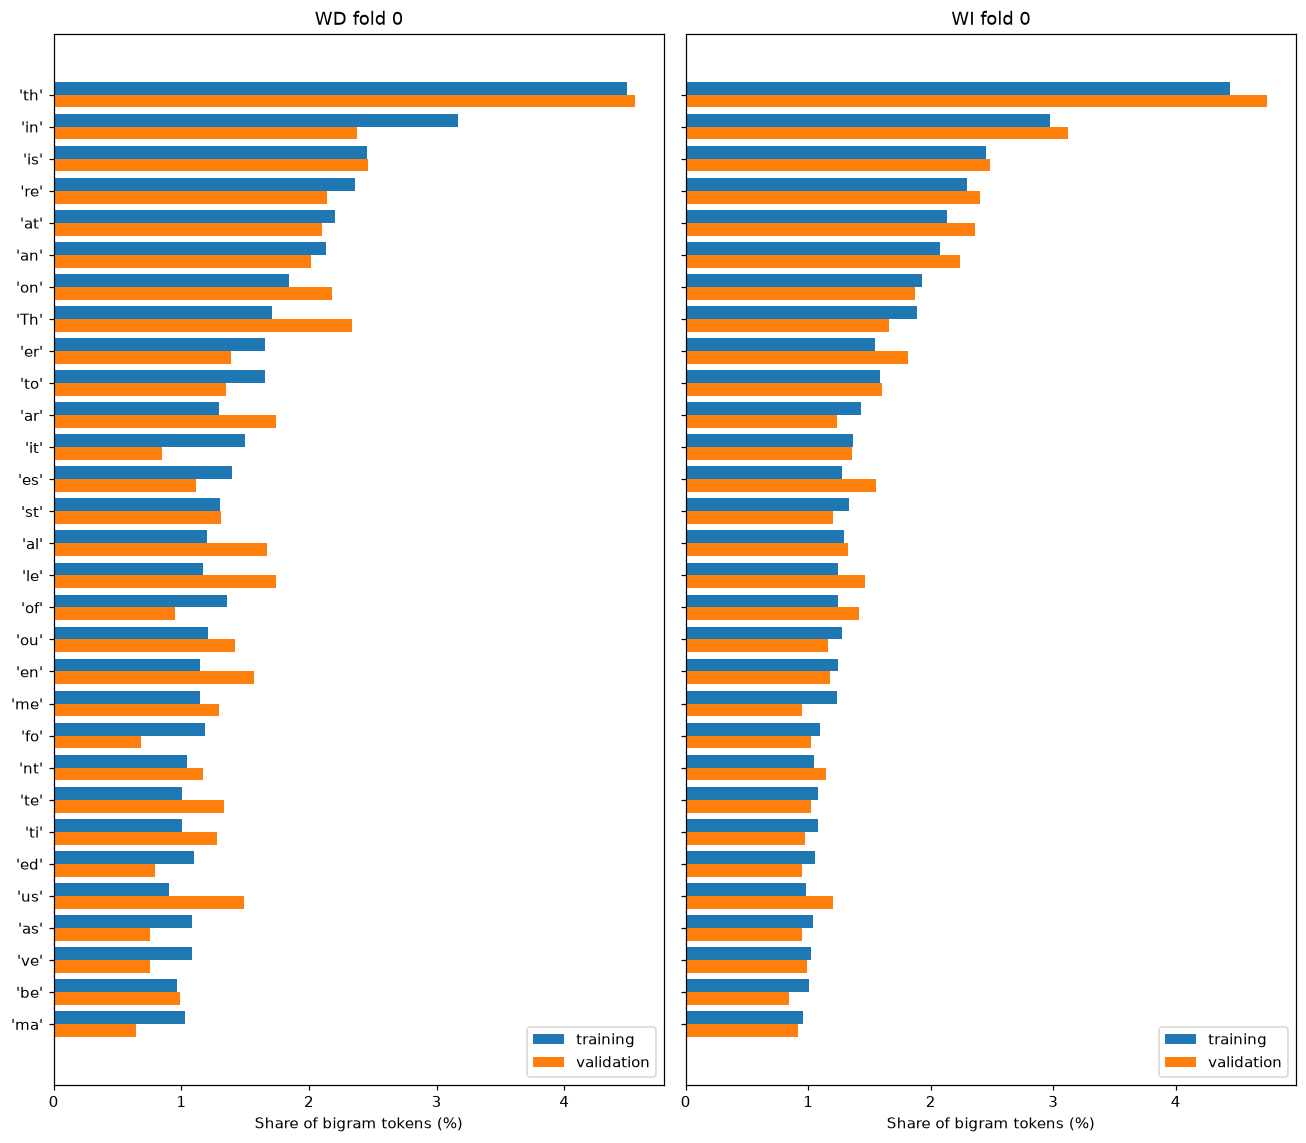

In [8]:
top = ranked[:TOP_N]
fig, axes = plt.subplots(1, len(SPLITS), figsize=(6 * len(SPLITS), 0.3 * len(top) + 1.5),
                         sharey=True, squeeze=False)
for ax, split in zip(axes[0], SPLITS):
    for k, part in enumerate(('train', 'val')):
        c = results[split][part]['bigrams']
        total = sum(c.values()) or 1
        ax.barh([i + (k - 0.5) * 0.4 for i in range(len(top))], [100 * c[t] / total for t in top],
                height=0.4, label='training' if part == 'train' else 'validation')
    ax.set_yticks(range(len(top)), [show(t) for t in top])
    ax.set_title(f'{split.upper()} fold {FOLD}')
    ax.set_xlabel('Share of bigram tokens (%)')
    ax.legend()
axes[0, 0].invert_yaxis()
plt.tight_layout()
plt.show()

## 4. How concentrated is bigram use?

Left: count of every vocabulary bigram, from most to least frequent. Right: the cumulative share. A curve that rises steeply and then flattens means a few bigrams carry most of the usage and many bigrams are rare.

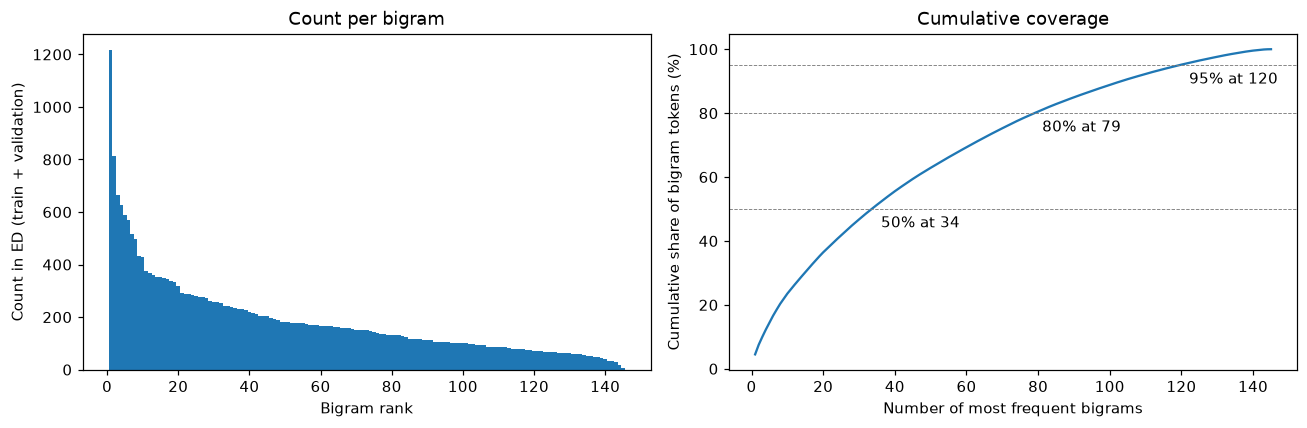

In [9]:
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4))
left.bar(range(1, len(ranked) + 1), [pooled[t] for t in ranked], width=1.0)
left.set_xlabel('Bigram rank')
left.set_ylabel('Count in ED (train + validation)')
left.set_title('Count per bigram')

shares, running = [], 0
for token in ranked:
    running += pooled[token]
    shares.append(100 * running / pooled_total)
right.plot(range(1, len(ranked) + 1), shares)
for share, rank in coverage.items():
    right.axhline(100 * share, color='grey', lw=0.6, ls='--')
    right.annotate(f'{int(100 * share)}% at {rank}', (rank, 100 * share), textcoords='offset points',
                   xytext=(5, -12))
right.set_xlabel('Number of most frequent bigrams')
right.set_ylabel('Cumulative share of bigram tokens (%)')
right.set_title('Cumulative coverage')
plt.tight_layout()
plt.show()

## 5. Summary in words

In [10]:
share =100 * pooled_total / (first['train']['tokens'] + first['val']['tokens'])
lines = [
    f'- Bigrams make up **{share:.1f}%** of all tokens when ED is encoded; the rest are single characters.',
    f'- **{len(bigrams) - len(unused)} of {len(bigrams)}** vocabulary bigrams occur in ED; {len(unused)} are never used.',
    f'- Use is concentrated: the 10 most frequent bigrams cover **{top10:.1f}%** of bigram tokens, '
    f'and **{coverage[0.8]}** bigrams cover 80%.',
]
for split in SPLITS:
    value = js_divergence(results[split]['train']['bigrams'], results[split]['val']['bigrams'])
    lines.append(f'- {split.upper()} fold {FOLD}: training and validation bigram frequencies differ by a divergence of '
                 f'**{value:.4f}** (0 = identical).')
display(Markdown('\n'.join(lines)))

- Bigrams make up **34.2%** of all tokens when ED is encoded; the rest are single characters.
- **145 of 145** vocabulary bigrams occur in ED; 0 are never used.
- Use is concentrated: the 10 most frequent bigrams cover **23.5%** of bigram tokens, and **79** bigrams cover 80%.
- WD fold 0: training and validation bigram frequencies differ by a divergence of **0.0322** (0 = identical).
- WI fold 0: training and validation bigram frequencies differ by a divergence of **0.0064** (0 = identical).